# Poisson 95% confidence intervals

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import curve_fit
from scipy.stats import chi2
from scipy.stats import norm

%matplotlib widget

## Settings

In [2]:
confint_percentage = 0.95
# confint_percentage = 0.9999
confint_stddev_low, confint_stddev_high = norm.interval(confint_percentage)

confint_percentage_half = (1 - confint_percentage) / 2
confint_percentile_low = confint_percentage_half
confint_percentile_high = 1 - confint_percentage_half


## Normal approximation

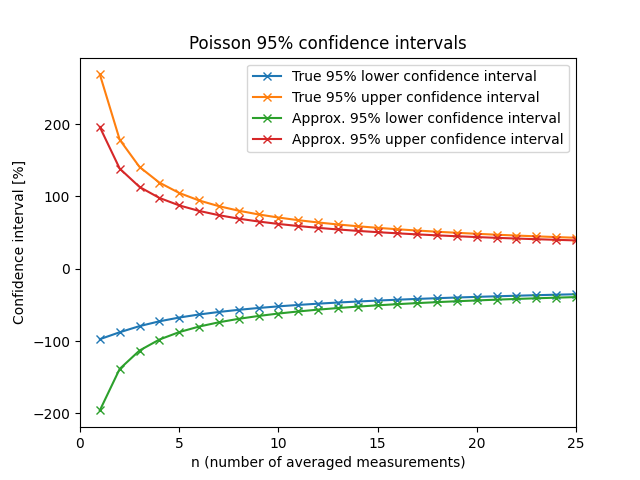

In [3]:
n = np.arange(1, 100000)

n_low = 0.5 * chi2.ppf(confint_percentile_low, df=2 * n)
n_high = 0.5 * chi2.ppf(confint_percentile_high, df=2 * n)

confint_low = (n_low - n) / n
confint_high = (n_high - n) / n

confint_low_approx = confint_stddev_low / np.sqrt(n)
confint_high_approx = confint_stddev_high / np.sqrt(n)

N_zoom = 25

plt.figure()
plt.title('Poisson 95% confidence intervals')
plt.xlabel('n (number of averaged measurements)')
plt.ylabel('Confidence interval [%]')
c1, = plt.plot(n, 100 * confint_low, marker='x', label='True 95% lower confidence interval')
c2, = plt.plot(n, 100 * confint_high, marker='x', label='True 95% upper confidence interval')
c3, = plt.plot(n, 100 * confint_low_approx, marker='x', label='Approx. 95% lower confidence interval')
c4, = plt.plot(n, 100 * confint_high_approx, marker='x', label='Approx. 95% upper confidence interval')
plt.xlim(0, N_zoom)
plt.legend(handles=[c1, c2, c3, c4], loc='upper right')
plt.show()

## Difference approximation

-0.97468219201571 2.6888794541139354
-0.8788953607280174 1.785821695469449
[ 0.97763241 -0.1168306 ]
[0.92095147 0.34074598]


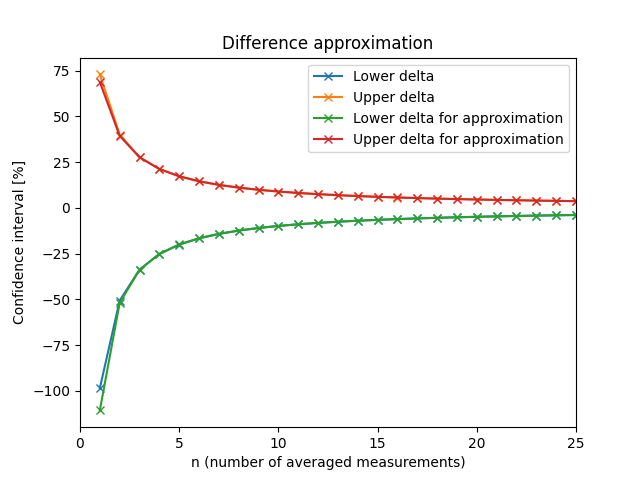

In [4]:
delta_low = confint_low - confint_low_approx
delta_high = confint_high - confint_high_approx

# Store first two values
print(confint_low[0], confint_high[0])
print(confint_low[1], confint_high[1])

def func(n, a, b):
    return a / (n + b)

# Approximate from third sample...
p_low, _ = curve_fit(func, n[2:], delta_low[2:])
p_high, _ = curve_fit(func, n[2:], delta_high[2:])

print(p_low)
print(p_high)

delta_low_approx = func(n, p_low[0], p_low[1])
delta_high_approx = func(n, p_high[0], p_high[1])

plt.figure()
plt.title('Difference approximation')
plt.xlabel('n (number of averaged measurements)')
plt.ylabel('Confidence interval [%]')
c1, = plt.plot(n, -100 * delta_low, marker='x', label='Lower delta')
c2, = plt.plot(n, 100 * delta_high, marker='x', label='Upper delta')
c3, = plt.plot(n,-100 * delta_low_approx, marker='x', label='Lower delta for approximation')
c4, = plt.plot(n, 100 * delta_high_approx, marker='x', label='Upper delta for approximation')
plt.xlim(0, N_zoom)
plt.legend(handles=[c1, c2, c3, c4], loc='upper right')
plt.show()

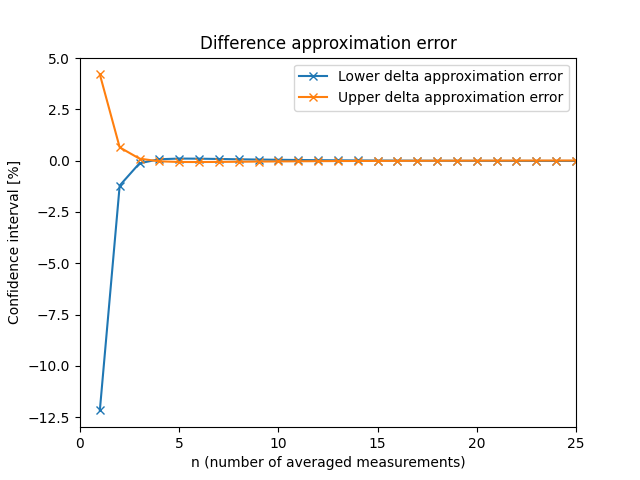

In [5]:
delta2_low = delta_low - delta_low_approx
delta2_high = delta_high - delta_high_approx

plt.figure()
plt.title('Difference approximation error')
plt.xlabel('n (number of averaged measurements)')
plt.ylabel('Confidence interval [%]')
c1, = plt.plot(n, 100 * delta2_low, marker='x', label='Lower delta approximation error')
c2, = plt.plot(n, 100 * delta2_high, marker='x', label='Upper delta approximation error')
plt.xlim(0, N_zoom)
plt.legend(handles=[c1, c2], loc='upper right')
plt.xlim(0, N_zoom)
plt.show()

## Firmware approximation

`getConfidenceInterval(n)` in `platform.io/src/system/cmath.c` returns the relative half-width of the 95% interval. It uses the upper interval, which is the wider side, as a symmetric ±: the normal approximation plus the fitted correction above, and the exact values for n = 1 and 2.

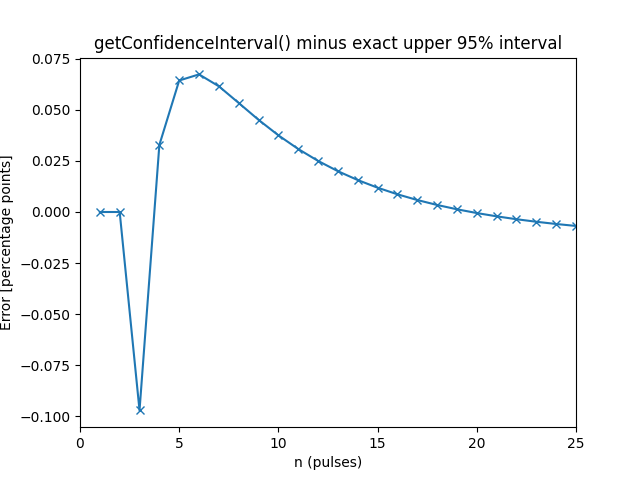

Largest error: 0.097 percentage points


In [6]:
def confidence_interval(n):
    """Port of getConfidenceInterval() (cmath.c)."""
    n = np.asarray(n, dtype=float)
    c = 1.959964 / np.sqrt(np.maximum(n, 1)) + 0.92095147 / (0.34074598 + n)
    c = np.where(n <= 2, 1.7858216, c)
    return np.where(n <= 1, 2.6888794, c)

error = confidence_interval(n) - confint_high

plt.figure()
plt.title('getConfidenceInterval() minus exact upper 95% interval')
plt.xlabel('n (pulses)')
plt.ylabel('Error [percentage points]')
plt.plot(n, 100 * error, marker='x')
plt.xlim(0, N_zoom)
plt.show()

print(f'Largest error: {100 * np.max(np.abs(error)):.3f} percentage points')

## Use in the measurements (Rad Pro 3.2)

With n pulses in a window of W seconds (t: time since the average started):

| Measurement | Estimate | Confidence |
|---|---|---|
| Instantaneous rate, adaptive, window ended by the pulse target | (n − 1) / W | c(n − 1) |
| Instantaneous rate, adaptive, longest available window | n / W | c(n) |
| Instantaneous rate, 1 minute | n / 60 s | c(n) |
| Average rate, timed | n / t | c(n) |
| Average rate, until a confidence level | (n − 1) / t | c(n − 1) |

A fixed window holds a Poisson count, so n / W is unbiased. A window ended by a pulse target is inverse sampling: the time T to the N-th pulse follows a Gamma(N) distribution, so (N − 1) / T is the unbiased estimate. With zero pulses the reading is 0 and no confidence is shown.

## Coverage

Fraction of the time the displayed interval, reading × (1 ± c), contains the true rate. For fixed windows the count n follows a Poisson distribution with mean μ. For windows ended by a pulse target, λT follows a Gamma(N) distribution, and the interval covers λ when λT lies within (N − 1)(1 ± c(N − 1)).

The firmware rounds windows to whole seconds and stores longer windows in 16 s steps; the Monte Carlo simulation in [measurement-sim](../measurement-sim/) gives 95-96% coverage for all modes.

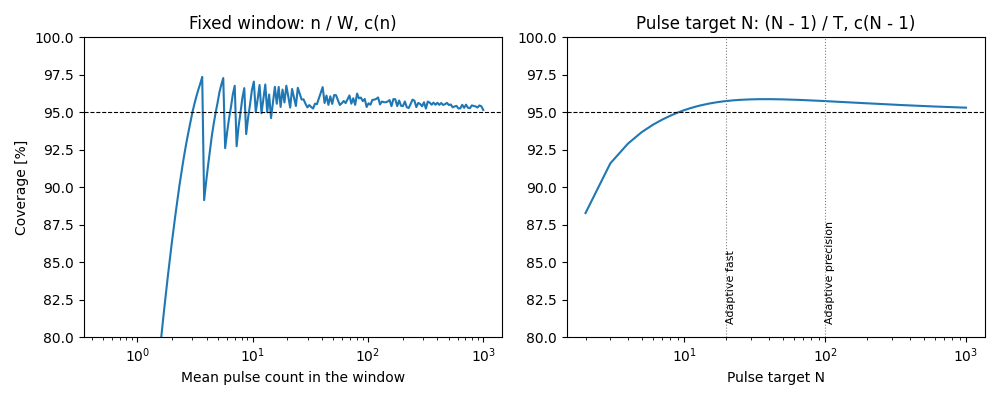

Pulse target 20: coverage 95.8%
Pulse target 100: coverage 95.7%
Fixed window, mean 5 pulses: coverage 95.8%
Fixed window, mean 20 pulses: coverage 96.4%
Fixed window, mean 100 pulses: coverage 95.5%


In [7]:
from scipy.stats import gamma, poisson

# Fixed window (1 minute, timed averages, longest adaptive window)
mu = np.logspace(-0.3, 3, 200)
k = np.arange(0, 3000)
covered = np.abs(k[None, :] - mu[:, None]) <= confidence_interval(k)[None, :] * k[None, :]
coverage_fixed = np.sum(poisson.pmf(k[None, :], mu[:, None]) * covered, axis=1)

# Window ended by a pulse target (adaptive averaging, average until a confidence level)
N = np.arange(2, 1001)
c_N = confidence_interval(N - 1)
coverage_target = gamma.cdf((N - 1) * (1 + c_N), N) - gamma.cdf((N - 1) * (1 - c_N), N)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))
ax1.semilogx(mu, 100 * coverage_fixed)
ax1.axhline(95, color='k', ls='--', lw=0.8)
ax1.set_title('Fixed window: n / W, c(n)')
ax1.set_xlabel('Mean pulse count in the window')
ax1.set_ylabel('Coverage [%]')
ax1.set_ylim(80, 100)
ax2.semilogx(N, 100 * coverage_target)
ax2.axhline(95, color='k', ls='--', lw=0.8)
for target, label in ((20, 'Adaptive fast'), (100, 'Adaptive precision')):
    ax2.axvline(target, color='gray', ls=':', lw=0.8)
    ax2.annotate(label, (target, 81), rotation=90, fontsize=8)
ax2.set_title('Pulse target N: (N - 1) / T, c(N - 1)')
ax2.set_xlabel('Pulse target N')
ax2.set_ylim(80, 100)
plt.tight_layout()
plt.show()

for target in (20, 100):
    print(f'Pulse target {target}: coverage {100 * coverage_target[target - 2]:.1f}%')
for mean in (5, 20, 100):
    print(f'Fixed window, mean {mean} pulses: coverage {100 * np.interp(mean, mu, coverage_fixed):.1f}%')

## Alert hysteresis

A rate alert starts when the reading reaches the threshold and ends when the reading falls below threshold / (1 + c), so the clear point follows the precision of the reading.

In [8]:
for name, count in (('Adaptive fast (20 pulses)', 19),
                    ('Adaptive precision (100 pulses)', 99),
                    ('1000 pulses', 1000),
                    ('10000 pulses', 10000)):
    c = float(confidence_interval(count))
    print(f'{name}: +/-{100 * c:.0f}%, alert ends below {1 / (1 + c):.2f} x threshold')

Adaptive fast (20 pulses): +/-50%, alert ends below 0.67 x threshold
Adaptive precision (100 pulses): +/-21%, alert ends below 0.83 x threshold
1000 pulses: +/-6%, alert ends below 0.94 x threshold
10000 pulses: +/-2%, alert ends below 0.98 x threshold


## Dead-time compensation

With a non-paralyzable dead time τ, the measured pulse intervals are τ plus an exponential interval, so the measured count m is less random than a Poisson count: its relative standard deviation is 1 / (√m (1 + λτ)). Compensation, n = m / (1 − mτ), multiplies the relative error by 1 / (1 − mτ) = 1 + λτ. Both factors cancel, so the confidence of the compensated rate is c(m) of the raw count, and the firmware needs no correction. Monte Carlo check at 5000 cps and 150 µs (compensation factor 1.75):

In [9]:
rng = np.random.default_rng(1)
lam, tau, seconds = 5000.0, 150e-6, 2000
intervals = tau + rng.exponential(1 / lam, int(seconds * lam / (1 + lam * tau) * 1.02))
times = np.cumsum(intervals)
m = np.bincount(times[times < seconds].astype(int), minlength=seconds)[:seconds]
compensated = m / (1 - m * tau)

print(f'Measured {m.mean():.0f} cps, compensated {compensated.mean():.0f} cps (true {lam:.0f} cps)')
print(f'Relative std dev: {100 * compensated.std() / lam:.2f}% '
      f'(1 / sqrt(m) = {100 / np.sqrt(m.mean()):.2f}%)')
covered = np.abs(compensated - lam) <= confidence_interval(m) * compensated
print(f'Coverage with c(m): {100 * covered.mean():.1f}%')

Measured 2857 cps, compensated 4999 cps (true 5000 cps)
Relative std dev: 1.82% (1 / sqrt(m) = 1.87%)
Coverage with c(m): 95.9%
